# 01. Klasifikasi URL MURL — Logistic Regression dengan TF-IDF karakter

Notebook ini melatih **Logistic Regression (one-vs-rest)** pada satu representasi URL. Dataset, split domain/IP, audit kebocoran host, dan fungsi transformasi fitur disalin verbatim dari notebook SVM teman, sehingga representasi yang dibandingkan identik. **Hanya metode training yang berbeda.**

Alur: lingkungan → audit data → split domain/IP + audit host → transformasi fitur → metode training → training final → validation → test → penyimpanan hasil → interpretasi.

Tiga file pendukung wajib ada di `DATA_DIR`: `Malicious URL Detection.csv`, `MURL_Split.csv`, `public_suffix_list.dat`.

**Sebelum menjalankan di Google Colab:** unggah ketiga file ke Drive, lalu sesuaikan `DATA_DIR` pada sel pertama. Lingkungan memakai `scikit-learn==1.9.1`, `tldextract==5.3.0`, dan `idna` agar sebanding dengan notebook SVM.

## 1. Persiapan lingkungan

Jalankan sel dari atas. Parameter model baru ditetapkan pada bagian metode, setelah preprocessing selesai.

In [16]:
!pip install -q scikit-learn==1.9.1 tldextract==5.3.0 idna threadpoolctl

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
import sys
import importlib.metadata
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()


DATA_DIR = Path("/content/drive/MyDrive/dataset ml ")

print("Interpreter aktif:", sys.executable)
print("Folder kerja    :", ROOT)
print("Folder data     :", DATA_DIR, "| ada:", DATA_DIR.is_dir())
versi = {nama: importlib.metadata.version(nama) for nama in
         ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "ipykernel", "tldextract", "idna"]}
display(pd.Series(versi, name="Versi terpasang").to_frame())


Interpreter aktif: /usr/bin/python3
Folder kerja    : /content
Folder data     : /content/drive/MyDrive/dataset ml  | ada: True


,Versi terpasang
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.9.1
matplotlib,3.10.0
ipykernel,6.17.1
tldextract,5.3.0
idna,3.20


## 2. Memeriksa file pendukung

In [4]:
for nama_file in ["Malicious URL Detection.csv", "MURL_Split.csv", "public_suffix_list.dat"]:
    jalur = DATA_DIR / nama_file
    print(f"{nama_file:32s} ada={jalur.is_file()}  ukuran={jalur.stat().st_size if jalur.is_file() else 0:,}")
assert (DATA_DIR / "Malicious URL Detection.csv").is_file(), "Dataset tidak ditemukan di DATA_DIR."
assert (DATA_DIR / "MURL_Split.csv").is_file(), "MURL_Split.csv tidak ditemukan di DATA_DIR."
assert (DATA_DIR / "public_suffix_list.dat").is_file(), "public_suffix_list.dat tidak ditemukan di DATA_DIR."


Malicious URL Detection.csv      ada=True  ukuran=51,681,357
MURL_Split.csv                   ada=True  ukuran=10,547,309
public_suffix_list.dat           ada=True  ukuran=338,012


## 3. Memuat, membersihkan, dan mengaudit data

Sel ini disalin verbatim dari notebook SVM; hanya nama folder data yang berbeda.

Seluruh 783,705 baris dimuat; tidak ada penghapusan atau pengambilan sampel.
URL dengan spasi ujung yang dibersihkan: 354
Salinan URL berulang yang tetap dipertahankan: 3


,Jumlah,Persentase
label,,
benign,426432,54.412
defacement,95263,12.155
exploit,243,0.031
legitimate,5809,0.741
malware,23592,3.010
phishing,229613,29.298
spam,2753,0.351


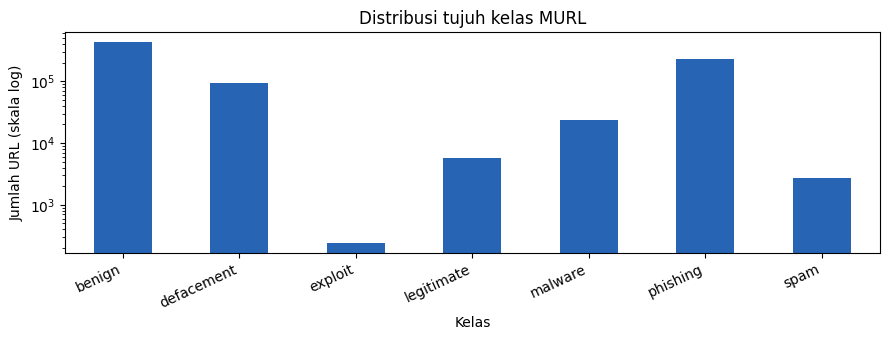

In [5]:
DATA_FILE = DATA_DIR / "Malicious URL Detection.csv"
raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
assert raw.columns.tolist() == ["url", "type"] and len(raw) == 783705
df = pd.DataFrame({"row_id": np.arange(len(raw)), "url": raw.url.str.strip(),
                   "label": raw.type.str.strip().str.lower()})
assert df.url.ne("").all() and df.label.ne("").all()
assert sorted(df.label.unique()) == ["benign", "defacement", "exploit", "legitimate", "malware", "phishing", "spam"]
assert df.groupby("url")["label"].nunique().max() == 1, "Ada label bertentangan untuk URL yang sama."
print(f"Seluruh {len(df):,} baris dimuat; tidak ada penghapusan atau pengambilan sampel.")
print("URL dengan spasi ujung yang dibersihkan:", int((raw.url != df.url).sum()))
print("Salinan URL berulang yang tetap dipertahankan:", int(df.url.duplicated().sum()))
counts = df.label.value_counts().sort_index()
display(pd.DataFrame({"Jumlah": counts, "Persentase": counts / len(df) * 100}).round(3))
fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.bar(ax=ax, logy=True, color="#2864b4")
ax.set(title="Distribusi tujuh kelas MURL", xlabel="Kelas", ylabel="Jumlah URL (skala log)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Pembagian data dan pemeriksaan kebocoran host

Split domain/IP `icann-domain-disjoint-v3` dibaca dari `MURL_Split.csv`; aturan public suffix dibaca dari `public_suffix_list.dat`. Sel ini disalin verbatim dari notebook SVM; hanya dua baris path yang berbeda.

In [6]:
import ipaddress
import re
import socket
from urllib.parse import urlsplit, unquote
import idna
import tldextract
VERSION = 'icann-domain-disjoint-v3'
ROLES = ('train', 'validation', 'test')
RATIOS = np.array([0.7, 0.15, 0.15])
MAX_OUTER_CLASS_ERROR = 0.005
MAX_TOTAL_ERROR = 0.001
SCHEME = re.compile('^(?:[A-Za-z][A-Za-z0-9+.-]*://|(?:mailto|data|javascript|tel|urn):)', re.I)
SPECIAL_SCHEME = re.compile('^(https?|ftp|ws|wss):[ \\t\\r\\n]*/*', re.I)
C0_SPACE = ''.join((chr(code) for code in range(33)))
NUMERIC_IP = re.compile('^(?:0x[0-9a-f]+|[0-9]+)(?:\\.(?:0x[0-9a-f]+|[0-9]+)){0,3}$', re.I)

def raw_hostname(value):
    value = value.replace('\\', '/').replace('\t', '').replace('\r', '').replace('\n', '').strip(C0_SPACE)
    match = SPECIAL_SCHEME.match(value)
    if match:
        value = match.group(1).lower() + '://' + value[match.end():]
    try:
        parsed = urlsplit(value if SCHEME.match(value) or value.startswith('//') else '//' + value)
        return (parsed.hostname or '').lower().rstrip('.')
    except ValueError:
        return ''

def host_site(host, extract):
    """ICANN eTLD+1 groups all subdomains/tenants; IP aliases use one literal key."""
    host = unquote(host).strip().lower().rstrip('.')
    if not host:
        return ('', 'unresolved-authority')
    try:
        canonical = idna.encode(host, uts46=True).decode('ascii').lower()
    except idna.IDNAError:
        canonical = host
    try:
        address = ipaddress.ip_address(canonical)
        if isinstance(address, ipaddress.IPv6Address) and address.ipv4_mapped is not None:
            address = address.ipv4_mapped
        return (str(address), 'ip:' + str(address))
    except ValueError:
        pass
    if NUMERIC_IP.fullmatch(canonical):
        try:
            address = str(ipaddress.IPv4Address(socket.inet_aton(canonical)))
            return (address, 'ip:' + address)
        except OSError:
            pass
    result = extract(canonical)
    root = result.top_domain_under_public_suffix or '.'.join(canonical.split('.')[-2:])
    try:
        root = idna.encode(root, uts46=True).decode('ascii').lower()
    except idna.IDNAError:
        return (canonical, 'unresolved-authority')
    return (canonical, 'domain:' + root)

def quality_report(urls, labels, hosts, site_ids, indices, classes):
    labels, urls = (np.asarray(labels), np.asarray(urls))
    total = pd.Series(labels).value_counts().reindex(classes).to_numpy()
    counts = np.array([pd.Series(labels[indices[role]]).value_counts().reindex(classes, fill_value=0).to_numpy() for role in ROLES])
    np.testing.assert_array_equal(np.sort(np.concatenate(list(indices.values()))), np.arange(len(urls)))
    assert (counts >= 30).all(), 'Setiap kelas harus terwakili dalam setiap partisi.'
    class_error = float(abs(counts / total - RATIOS[:, None]).max())
    total_error = float(abs(counts.sum(axis=1) / len(urls) - RATIOS).max())
    assert class_error <= MAX_OUTER_CLASS_ERROR and total_error <= MAX_TOTAL_ERROR
    overlap = {}
    for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        a, b = (indices[first], indices[second])
        item = {'site_groups': len(set(site_ids[a]) & set(site_ids[b])), 'hostnames': len(set(hosts[a]) - {''} & set(hosts[b]) - {''}), 'stripped_urls': len(set(urls[a]) & set(urls[b]))}
        assert not any(item.values()), (first, second, item)
        overlap[first + '_vs_' + second] = item
    domain_counts = np.array([[len(np.unique(site_ids[indices[role]][labels[indices[role]] == label])) for label in classes] for role in ROLES])
    assert (domain_counts >= 10).all()
    return {'version': VERSION, 'rows': len(urls), 'site_groups': int(len(np.unique(site_ids))), 'targets': dict(zip(ROLES, RATIOS.tolist())), 'outer_rows': {role: len(indices[role]) for role in ROLES}, 'class_counts': {label: {role: int(counts[i, j]) for i, role in enumerate(ROLES)} for j, label in enumerate(classes)}, 'class_site_counts': {label: {role: int(domain_counts[i, j]) for i, role in enumerate(ROLES)} for j, label in enumerate(classes)}, 'max_outer_class_allocation_error': class_error, 'max_outer_total_error': total_error, 'overlap': overlap}

def load_partitions(df):
    split_file = DATA_DIR / 'MURL_Split.csv'
    psl_file = DATA_DIR / 'public_suffix_list.dat'
    if not split_file.is_file() or not psl_file.is_file():
        raise FileNotFoundError('Letakkan MURL_Split.csv dan public_suffix_list.dat bersama notebook dan CSV dataset.')
    assignment = pd.read_csv(split_file, dtype={'row_id': np.int64, 'split': str}, keep_default_na=False)
    assert assignment.columns.tolist() == ['row_id', 'split']
    assert len(assignment) == len(df) == 783705
    np.testing.assert_array_equal(assignment['row_id'], np.arange(len(df)))
    assert set(assignment['split']) == set(ROLES)
    indices = {role: assignment.loc[assignment['split'] == role, 'row_id'].to_numpy() for role in ROLES}
    extract = tldextract.TLDExtract(suffix_list_urls=[psl_file.resolve().as_uri()], cache_dir=None, fallback_to_snapshot=False, include_psl_private_domains=False)
    raw_hosts = df.url.map(raw_hostname)
    lookup = {host: host_site(host, extract) for host in raw_hosts.unique()}
    hosts = raw_hosts.map(lambda host: lookup[host][0]).to_numpy()
    keys = raw_hosts.map(lambda host: lookup[host][1]).to_numpy()
    site_keys, site_ids = np.unique(keys, return_inverse=True)
    site_ids = site_ids.astype(np.int32)
    classes = sorted(df.label.unique())
    quality = quality_report(df.url.to_numpy(), df.label.to_numpy(), hosts, site_ids, indices, classes)
    quality['unresolved_rows'] = int(np.sum(keys == 'unresolved-authority'))
    return {'indices': indices, 'site_id': site_ids, 'site_keys': site_keys.tolist(), 'hosts': hosts, 'quality': quality, 'version': VERSION}


**Sel penerapan split:** memeriksa penugasan tiap baris, representasi semua kelas, dan tidak adanya irisan domain/IP, hostname, maupun URL. Tabel di bawah harus menunjukkan nol overlap.

In [7]:
design = load_partitions(df)
df["site_id"] = design["site_id"]
df["partisi"] = ""
for role, ids in design["indices"].items():
    df.loc[ids, "partisi"] = role
np.testing.assert_array_equal(
    np.sort(np.concatenate(list(design["indices"].values()))), np.arange(len(df)))
split_counts = pd.crosstab(df.label, df.partisi).reindex(columns=["train", "validation", "test"])
assert (split_counts > 0).all().all() and split_counts.to_numpy().sum() == len(df)
display(split_counts.rename(columns={"train": "Latih", "validation": "Validation", "test": "Test"}))
display(pd.DataFrame(design["quality"]["overlap"]).T)


partisi,Latih,Validation,Test
label,,,
benign,298498,63965,63969
defacement,66674,14295,14294
exploit,170,37,36
legitimate,4066,871,872
malware,16517,3541,3534
phishing,160738,34438,34437
spam,1929,412,412


,site_groups,hostnames,stripped_urls
train_vs_validation,0,0,0
train_vs_test,0,0,0
validation_vs_test,0,0,0


### 2.3 Transformasi fitur — TF-IDF karakter

#### TF-IDF karakter: dari teks URL menjadi matriks angka

1. **Pertahankan teks URL** setelah membuang spasi di ujung. Huruf besar/kecil dipertahankan (`lowercase=False`) karena path/query dapat peka terhadap kapitalisasi. Tidak ada penghapusan stopword, pemotongan URL, atau decoding tambahan.
2. **Pecah menjadi karakter 3–5 gram** yang saling bertumpang tindih. Contoh `login`: 3-gram `log`, `ogi`, `gin`; 4-gram `logi`, `ogin`; 5-gram `login`. Angka dan tanda baca ikut menjadi pola. Rentang ini menggabungkan fragmen pendek dan konteks lebih panjang tanpa memerlukan batas kata.
3. **Pelajari kosakata dari data train saja.** `min_df=2` mengabaikan pola yang hanya muncul pada satu URL latih. `max_features=75000` membatasi kosakata pada paling banyak 75.000 pola berdasarkan frekuensi total dalam korpus latih. Ini batas jumlah kolom, **bukan batas jumlah URL**; seluruh baris tetap digunakan. Pola baru di validation/test yang tidak ada dalam kosakata diabaikan.
4. **Hitung bobot TF-IDF.** Frekuensi kemunculan diubah menjadi `1 + ln(tf)` (`sublinear_tf=True`). Dengan pemulusan bawaan, `idf = ln((1 + n) / (1 + df)) + 1`, dengan `n` jumlah dokumen latih dan `df` jumlah dokumen latih yang memuat pola. Bobot sebelum normalisasi adalah `tf × idf`.
5. **L2 normalization per URL** sehingga panjang vektor tak nol menjadi satu. Hasil berupa matriks sparse `float32`; nilai nol tidak disimpan satu per satu. TF-IDF tidak diteruskan ke StandardScaler.

**Mengapa 3–5 dan 75.000?** Keduanya diwarisi dari eksperimen SVM sebagai konfigurasi awal untuk menyeimbangkan pola yang ditangkap, memori, dan waktu komputasi. Angka ini **belum dibuktikan optimal**. N-gram lebih panjang memperluas kosakata dan dapat menghafal fragmen spesifik; batas fitur terlalu kecil dapat membuang pola kelas langka. Perbandingan model mempertahankan nilai ini supaya preprocessing tetap sama. Pencarian nilai terbaik harus memakai train/validation saja, kemudian dinilai pada holdout baru; jangan memilihnya dari skor test.

Referensi: [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).


**Penjelasan sel kode berikut:** factory membuat objek TF-IDF dengan konfigurasi bersama, lalu `build_analyzer` memperlihatkan contoh n-gram dari `login`. Objek ini belum di-fit dan belum mempunyai kosakata/IDF dari dataset. Fitting kosakata/IDF dilakukan hanya pada bagian fitting train penuh saat training final; validation/test memakai transformasi yang sudah dipelajari itu.

Objek pada sel ini adalah pratinjau konfigurasi. Saat training final, pipeline membuat objek baru melalui factory yang sama; statistik fitting hanya dipelajari dari train.

**Sel definisi fungsi:** menyediakan transformasi reusable di dalam notebook. Fungsi hanya membuat objek baru yang belum di-fit; statistik dataset belum dipelajari.


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer


def make_preprocessing(representation="tfidf"):
    if representation != "tfidf":
        raise ValueError("Notebook ini memakai TF-IDF.")
    return TfidfVectorizer(
        analyzer="char", ngram_range=(3, 5), lowercase=False,
        min_df=2, max_features=75000, sublinear_tf=True,
        norm="l2", dtype=np.float32,
    )


**Sel contoh penggunaan:** buat satu objek preprocessing, tampilkan konfigurasinya, dan amati contoh transformasi. Ini menunjukkan cara kerja fitur tanpa melakukan fitting pada seluruh dataset. model final akan membuat objek baru melalui fungsi yang sama.


In [9]:
REPRESENTATION = "tfidf"
preprocessing = make_preprocessing(REPRESENTATION)
print(preprocessing)
print("Contoh n-gram untuk login:", preprocessing.build_analyzer()("login"))
print("Kosakata dan IDF belum dipelajari; belum ada fit pada dataset penuh.")


TfidfVectorizer(analyzer='char', dtype=<class 'numpy.float32'>, lowercase=False,
                max_features=75000, min_df=2, ngram_range=(3, 5),
                sublinear_tf=True)
Contoh n-gram untuk login: ['log', 'ogi', 'gin', 'logi', 'ogin', 'login']
Kosakata dan IDF belum dipelajari; belum ada fit pada dataset penuh.


## 4. Metode training

Logistic Regression dilatih sebagai **one-vs-rest**: tujuh model biner, satu per kelas. `solver='liblinear'` tidak menerima target multiclass pada scikit-learn 1.9, sehingga `OneVsRestClassifier` dipakai agar skema tetap satu-lawan-sisanya. `C=1.0` dan `class_weight='balanced'` disamakan dengan notebook SVM. Peringatan konvergensi menghentikan proses.

Mulai bagian ini, metode boleh berbeda. Data, preprocessing, split, dan evaluasi tetap sama. Parameter ditetapkan sebelum membaca skor validation/test; tidak ada pencarian hyperparameter.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

MODEL_FAMILY = 'logreg'
SEED = 42
LABEL_MODEL = {MODEL_FAMILY: 'Logistic Regression (one-vs-rest)'}
LR_SETTINGS = dict(C=1.0, class_weight='balanced', solver='liblinear',
                   dual=False, tol=1e-4, max_iter=1000, random_state=SEED)


def make_classifier(family):
    if family != MODEL_FAMILY:
        raise ValueError("Pilih metode yang sesuai dengan notebook ini.")
    # liblinear tidak menerima target multiclass, jadi dibungkus one-vs-rest:
    # tujuh model biner LogisticRegression, satu per kelas.
    return OneVsRestClassifier(LogisticRegression(**LR_SETTINGS))


def kernel_settings(family):
    return None

display(pd.Series(LR_SETTINGS, name="Parameter metode").to_frame())
pemetaan_kernel = kernel_settings(MODEL_FAMILY)
if pemetaan_kernel is not None:
    display(pd.Series(pemetaan_kernel, name="Parameter pemetaan kernel").to_frame())


,Parameter metode
C,1.0
class_weight,balanced
solver,liblinear
dual,False
tol,0.0001
max_iter,1000
random_state,42


**Sel fungsi training dan evaluasi bersama:** pembuatan pipeline, fitting train, fitting model final, perhitungan metrik, confusion matrix, penyimpanan prediksi, dan interpretasi. Isinya disalin dari notebook SVM dengan dua penyesuaian kecil untuk `OneVsRestClassifier`.

In [11]:
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
import json
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
# Hasil disimpan di samping dataset agar tetap ada setelah runtime Colab reset.
RESULTS = DATA_DIR / "results_logreg_disjoint"
VERSIONS = versi
LABEL_REP = {'tfidf': 'TF-IDF karakter', 'feature_engineering': '54 fitur numerik URL'}

def make_model(family, representation):
    steps = [('preprocessing', make_preprocessing(representation))]
    mapping = kernel_settings(family)
    if mapping is not None:
        steps.append(('kernel_map', ClassBalancedNystroem(**mapping)))
    steps.append(('classifier', make_classifier(family)))
    return Pipeline(steps)

def fit_model(model, urls, labels):
    with warnings.catch_warnings(), threadpool_limits(limits=4):
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(urls, labels)
    classifier = model.named_steps['classifier']
    if isinstance(classifier, OneVsRestClassifier):
        assert len(classifier.estimators_) == len(classifier.classes_)
        iterations = [int(est.n_iter_[0]) for est in classifier.estimators_]
        assert max(iterations) < LR_SETTINGS['max_iter'], iterations
    if 'kernel_map' in model.named_steps:
        mapper = model.named_steps['kernel_map']
        assert mapper.fit_input_rows_ == len(urls)
        assert len(set(mapper.landmark_indices_)) == mapper.n_components_
    return model

def save_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')
    temporary.replace(path)

def metrics(truth, prediction, classes):
    return {'accuracy': float(accuracy_score(truth, prediction)), 'balanced_accuracy': float(balanced_accuracy_score(truth, prediction)), 'macro_f1': float(f1_score(truth, prediction, labels=classes, average='macro', zero_division=0)), 'weighted_f1': float(f1_score(truth, prediction, labels=classes, average='weighted', zero_division=0))}

def report_frame(report, classes):
    records = {label: report[label] for label in classes + ['macro avg', 'weighted avg']}
    frame = pd.DataFrame(records).T
    return frame.rename(columns={'precision': 'Precision', 'recall': 'Recall', 'f1-score': 'F1', 'support': 'Support'}, index={'macro avg': 'Macro average', 'weighted avg': 'Weighted average'})

def context(family, representation, df, design):
    return {'model': family, 'representation': representation, 'split_design_version': 'icann-domain-disjoint-v3', 'row_count': len(df), 'classes': sorted(df.label.unique()), 'seed': SEED, 'versions': VERSIONS, 'classifier_settings': make_classifier(family).estimator.get_params(),
            'decomposition': 'one-vs-rest, 7 binary liblinear models', 'kernel_settings': kernel_settings(family), 'preprocessing': repr(make_preprocessing(representation)), 'split_counts': {role: int(len(ids)) for role, ids in design['indices'].items()}}

def fit_final(family, representation, df, design):
    """Fit preprocessing dan model pada seluruh train; validation/test dikecualikan."""
    meta = context(family, representation, df, design)
    save_json(RESULTS / f'{family}_{representation}_metrics.json', {**meta, 'completed': False, 'run_id': uuid4().hex})
    ids = design['indices']['train']
    model = make_model(family, representation)
    print(f'Melatih {LABEL_MODEL[family]} pada seluruh {len(ids):,} baris train...', flush=True)
    started = perf_counter()
    fit_model(model, df.url.iloc[ids], df.label.iloc[ids])
    seconds = perf_counter() - started
    classifier = model.named_steps['classifier']
    assert classifier.classes_.tolist() == meta['classes']
    assert len(classifier.estimators_) == len(meta['classes'])
    iterations = [int(est.n_iter_[0]) for est in classifier.estimators_]
    assert max(iterations) < LR_SETTINGS['max_iter'], iterations
    print('Iterasi solver per kelas:', iterations)
    if representation == 'feature_engineering':
        assert model.named_steps['preprocessing'].named_steps['scaler'].n_samples_seen_ == len(ids)
    print(f"Selesai dalam {seconds:.1f} detik; jumlah fitur: {model.named_steps['classifier'].n_features_in_:,}.")
    return (model, seconds)

def evaluate(model, role, df, design):
    ids = design['indices'][role]
    truth = df.label.iloc[ids]
    classes = sorted(df.label.unique())
    started = perf_counter()
    prediction = model.predict(df.url.iloc[ids])
    seconds = perf_counter() - started
    score = metrics(truth, prediction, classes)
    report = classification_report(truth, prediction, labels=classes, output_dict=True, zero_division=0)
    cm = confusion_matrix(truth, prediction, labels=classes)
    assert cm.sum() == len(ids)
    title = 'Validation' if role == 'validation' else 'Test'
    print(f'{title}: {len(ids):,} baris; prediksi {seconds:.1f} detik.')
    display(pd.DataFrame([score], index=[title]).round(4))
    display(report_frame(report, classes).round(4))
    if role == 'test':
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        for ax, matrix, name, fmt in [(axes[0], cm, 'Jumlah prediksi', 'd'), (axes[1], cm / cm.sum(axis=1, keepdims=True), 'Recall per kelas', '.2f')]:
            ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45, values_format=fmt)
            ax.set(title=f'Confusion matrix — {name}', xlabel='Predicted class', ylabel='Actual class')
        plt.tight_layout()
        plt.show()
        i = classes.index('exploit')
        print(f'Kelas exploit: {cm[i, i]}/{cm[i].sum()} terdeteksi. Perhatikan jumlah contoh yang kecil.')
    return {'metrics': score, 'report': report, 'confusion_matrix': cm.tolist(), 'predict_seconds': seconds, 'prediction': prediction}

def save_result(family, representation, model, fit_seconds, validation, test, df, design):
    meta = context(family, representation, df, design)
    key = f'{family}_{representation}'
    run_id = uuid4().hex
    files = {}
    for role, result in [('validation', validation), ('test', test)]:
        path = RESULTS / f'{key}_{role}_predictions.csv.gz'
        ids = design['indices'][role]
        pd.DataFrame({'row_id': ids, 'y_true': df.label.iloc[ids].to_numpy(), 'y_pred': result['prediction'], 'run_id': run_id}).to_csv(path, index=False, compression='gzip')
        files[role] = path.name
    summary = {**meta, 'completed': True, 'run_id': run_id, 'fit_seconds': fit_seconds, 'solver_iterations': [int(est.n_iter_[0]) for est in model.named_steps['classifier'].estimators_], 'input_features': int(model.named_steps['classifier'].n_features_in_), 'validation': validation['metrics'], 'test': test['metrics'], 'validation_report': validation['report'], 'test_report': test['report'], 'test_confusion_matrix': test['confusion_matrix'], 'prediction_files': files, 'completed_at_utc': datetime.now(timezone.utc).isoformat()}
    save_json(RESULTS / f'{key}_metrics.json', summary)
    report_frame(test['report'], meta['classes']).to_csv(RESULTS / f'{key}_test_report.csv')
    return summary

def interpretation(summary):
    report, classes = (summary['test_report'], summary['classes'])
    weakest = min(classes, key=lambda label: report[label]['f1-score'])
    print(f"{LABEL_MODEL[summary['model']]} + {LABEL_REP[summary['representation']]}:")
    print(f"Accuracy test {summary['test']['accuracy']:.2%}; macro F1 {summary['test']['macro_f1']:.4f}.")
    print(f"Kelas dengan F1 terendah: {weakest} ({report[weakest]['f1-score']:.4f}).")
    print('Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi. Hasil berlaku pada protokol ini; data tidak memuat timestamp, source, atau campaign.')


## 5. Melatih model final pada seluruh train

Pipeline baru difit pada seluruh 548.592 baris train. Validation dan test tetap dikecualikan.

In [12]:
model, fit_seconds = fit_final(MODEL_FAMILY, REPRESENTATION, df, design)


Melatih Logistic Regression (one-vs-rest) pada seluruh 548,592 baris train...
Iterasi solver per kelas: [7, 9, 12, 9, 10, 8, 11]
Selesai dalam 493.1 detik; jumlah fitur: 75,000.


## 6. Evaluasi validation

Accuracy, balanced accuracy, macro F1, weighted F1, serta precision/recall/F1 per kelas. Hasil validation hanya untuk diagnosis; konfigurasi tidak diubah.

In [13]:
validation = evaluate(model, "validation", df, design)


Validation: 117,559 baris; prediksi 16.1 detik.


,accuracy,balanced_accuracy,macro_f1,weighted_f1
Validation,0.858,0.6609,0.6594,0.8633


,Precision,Recall,F1,Support
benign,0.9130,0.8815,0.8970,63965.0
defacement,0.9339,0.7989,0.8611,14295.0
exploit,0.8824,0.4054,0.5556,37.0
legitimate,0.1796,0.5913,0.2755,871.0
malware,0.9073,0.8128,0.8574,3541.0
phishing,0.7925,0.8575,0.8237,34438.0
spam,0.4528,0.2791,0.3453,412.0
Macro average,0.7231,0.6609,0.6594,117559.0
Weighted average,0.8730,0.8580,0.8633,117559.0


## 7. Evaluasi test

Partisi test sama pada seluruh notebook. Confusion matrix menempatkan kelas sebenarnya pada baris dan kelas prediksi pada kolom. Test hanya memuat 36 contoh exploit; interval kepercayaan kelas ini lebar.

Test: 117,554 baris; prediksi 18.0 detik.


,accuracy,balanced_accuracy,macro_f1,weighted_f1
Test,0.8282,0.7093,0.6904,0.8356


,Precision,Recall,F1,Support
benign,0.9100,0.8282,0.8672,63969.0
defacement,0.9370,0.8300,0.8802,14294.0
exploit,0.8214,0.6389,0.7188,36.0
legitimate,0.1639,0.5573,0.2533,872.0
malware,0.7913,0.7286,0.7587,3534.0
phishing,0.7291,0.8484,0.7842,34437.0
spam,0.6128,0.5340,0.5707,412.0
Macro average,0.7094,0.7093,0.6904,117554.0
Weighted average,0.8501,0.8282,0.8356,117554.0


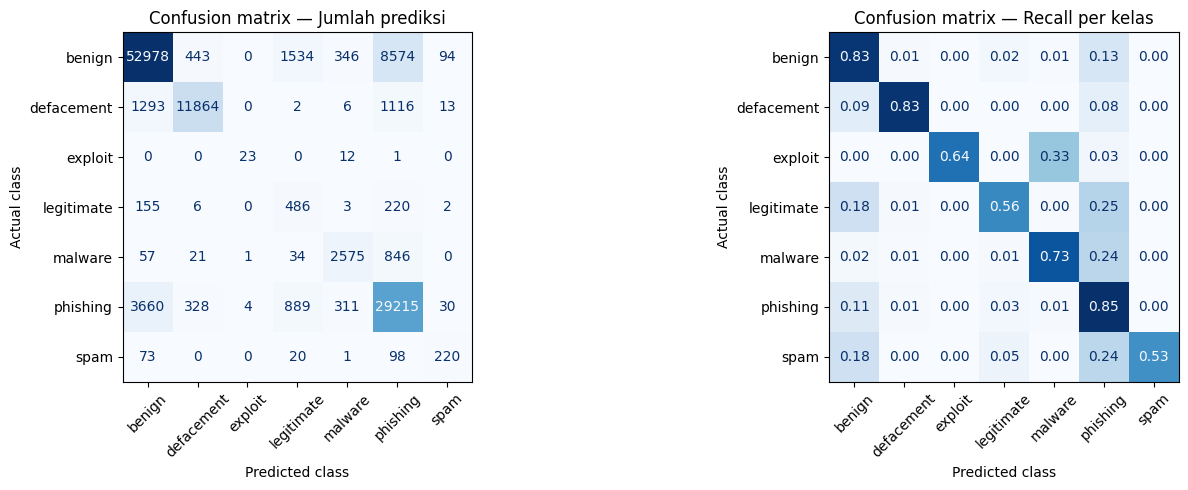

Kelas exploit: 23/36 terdeteksi. Perhatikan jumlah contoh yang kecil.


In [14]:
test = evaluate(model, "test", df, design)


## 8. Menyimpan hasil

Hasil ditulis ke `results_logreg_disjoint/`: prediksi validation/test per baris, laporan per kelas, parameter, versi pustaka, dan identitas baris.

In [15]:
summary = save_result(MODEL_FAMILY, REPRESENTATION, model, fit_seconds,
                      validation, test, df, design)
interpretation(summary)
del model, validation, test
gc.collect()


Logistic Regression (one-vs-rest) + TF-IDF karakter:
Accuracy test 82.82%; macro F1 0.6904.
Kelas dengan F1 terendah: legitimate (0.2533).
Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi. Hasil berlaku pada protokol ini; data tidak memuat timestamp, source, atau campaign.


11129

## 9. Interpretasi

Isi bagian ini setelah notebook dijalankan, memakai hanya angka yang tercetak di atas.

- Bandingkan dengan notebook SVM pada representasi yang sama; split, preprocessing, dan metrik identik, sehingga selisih mencerminkan metode training.
- Laporkan macro F1 dan balanced accuracy lebih dulu; accuracy dapat didominasi kelas besar.
- Perhatikan `legitimate` dan `spam` yang jumlahnya kecil; precision dapat turun tajam akibat `class_weight='balanced'`.
- `exploit` hanya 36 baris test, sehingga recall-nya memiliki interval lebar.
- Split bersifat domain/IP-disjoint; hasil tetap bukan bukti generalisasi ke ancaman masa depan karena data tidak memuat waktu, sumber, atau kampanye.